# Vidal et al. (2019) Case 1
Independent scratch training for Panasonic 18650PF, LG HG2, and Samsung 30T: `full_train -> test`. SOC v2 is a cycler-derived benchmark reference, not independently measured ground truth. Sequence length, min-max normalisation, and shuffle are reconstruction assumptions. This notebook starts with smoke mode; it does not launch 515 epochs automatically.

In [3]:
!git clone https://github.com/zhangcastle/battery-soc-transfer-benchmark.git /content/battery-soc-transfer-benchmark
!pip install -q -r /content/battery-soc-transfer-benchmark/requirements-colab.txt
!pip install -q -e /content/battery-soc-transfer-benchmark

Cloning into '/content/battery-soc-transfer-benchmark'...
remote: Enumerating objects: 940, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (48/48), done.
remote: Total 940 (delta 21), reused 53 (delta 19), pack-reused 871 (from 2)
Receiving objects: 100% (940/940), 267.85 MiB | 18.74 MiB/s, done.
Resolving deltas: 100% (420/420), done.
Updating files: 100% (562/562), done.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for battery-benchmark (pyproject.toml) ... done


In [4]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import hashlib, json, subprocess, sys
from datetime import datetime, timezone
REPO_ROOT = Path('/content/battery-soc-transfer-benchmark')
DRIVE_ROOT = Path('/content/drive/MyDrive/battery_soc_benchmark')
VIDAL_V2_ROOT = DRIVE_ROOT / 'data/labelled/vidal_sequence_v2'
CASE1_OUTPUT_ROOT = DRIVE_ROOT / 'outputs/vidal_case1'
LOCAL_CACHE_ROOT = Path('/content/battery_soc_cache/vidal_sequence_v2')
if not REPO_ROOT.is_dir():
    raise FileNotFoundError(
        f'Missing repo: {REPO_ROOT}. Run notebooks/00_colab_setup.ipynb first, '
        'or clone https://github.com/zhangcastle/battery-soc-transfer-benchmark.git to /content.'
    )
sys.path.insert(0, str(REPO_ROOT / 'src'))
print('Paths configured:', VIDAL_V2_ROOT, CASE1_OUTPUT_ROOT, sep='\n')

Mounted at /content/drive
Paths configured:
/content/drive/MyDrive/battery_soc_benchmark/data/labelled/vidal_sequence_v2
/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1


## Git and Drive preflight

In [5]:
from battery_benchmark.data.vidal_sequence_v2_dataset import validate_case1_roots
commit = subprocess.check_output(['git','rev-parse','HEAD'], cwd=REPO_ROOT, text=True).strip()
dirty = bool(subprocess.check_output(['git','status','--porcelain'], cwd=REPO_ROOT, text=True).strip())
checks = validate_case1_roots(VIDAL_V2_ROOT)
display(checks)
assert (checks.status == 'PASS').all(), 'Required Drive input is missing'
CASE1_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
test_path = CASE1_OUTPUT_ROOT / '.case1_drive_write_test.json'
payload = {'utc_timestamp': datetime.now(timezone.utc).isoformat(), 'git_commit': commit, 'git_dirty': dirty, 'repository': REPO_ROOT.name, 'marker': 'battery_soc_case1_drive_test'}
encoded = json.dumps(payload, sort_keys=True).encode()
test_path.write_bytes(encoded)
assert test_path.read_bytes() == encoded
print('Drive mount: PASS; Output create: PASS; Test write/readback: PASS')
print('SHA-256:', hashlib.sha256(encoded).hexdigest())
test_path.unlink(); assert not test_path.exists(); print('Cleanup: PASS')
print('Commit:', commit, 'dirty:', dirty)

,dataset,split,index,metadata,concatenated,records,status
0,panasonic_18650pf,full_train,True,True,True,True,PASS
1,panasonic_18650pf,partial_train,True,True,True,True,PASS
2,panasonic_18650pf,test,True,True,True,True,PASS
3,lg_hg2,full_train,True,True,True,True,PASS
4,lg_hg2,partial_train,True,True,True,True,PASS
5,lg_hg2,test,True,True,True,True,PASS
6,samsung_30t,full_train,True,True,True,True,PASS
7,samsung_30t,partial_train,True,True,True,True,PASS
8,samsung_30t,test,True,True,True,True,PASS


Drive mount: PASS; Output create: PASS; Test write/readback: PASS
SHA-256: d1bd116cebbb9301ff6886f0e26cdf6ec45ab0b75d5a438861c8bcd70047516c
Cleanup: PASS
Commit: c4728bbaf60430f31640fc0f20958feabefb8c53 dirty: False


## Inventory and QC (read-only)

In [6]:
from battery_benchmark.data.vidal_sequence_v2_dataset import VidalSequenceV2Dataset
for dataset in ['panasonic_18650pf','lg_hg2','samsung_30t']:
    train = VidalSequenceV2Dataset(VIDAL_V2_ROOT, dataset, 'full_train')
    test = VidalSequenceV2Dataset(VIDAL_V2_ROOT, dataset, 'test')
    print(dataset, {'train_records': len(train.records), 'test_records': len(test.records), 'train_status': train.inventory.label_qc_status.value_counts().to_dict(), 'test_status': test.inventory.label_qc_status.value_counts().to_dict()})
    display(train.inventory.head())

panasonic_18650pf {'train_records': 9, 'test_records': 6, 'train_status': {'PASS': 8, 'WARNING': 1}, 'test_status': {'PASS': 5, 'WARNING': 1}}


,dataset,protocol_split,sequence_order,sequence_segment_id,source_filename,file_type,paper_profile,n_samples,duration_s,soc_start,soc_end,voltage_min,voltage_max,current_min,current_max,temperature_min,temperature_max,label_qc_status,warning_reasons,record_sha256
0,panasonic_18650pf,full_train,1,1,03-18-17_02.17 25degC_Cycle_1_Pan18650PF.mat,drive_cycle,Cycle_1,109641,10983.911998,1.000000,0.070148,2.50205,4.21744,-19.43637,10.70564,21.770408,30.02432,PASS,duplicate_dt_count=4,1f0339119162337c0b24e27aa07072f5dabd1fa3d6e8ad...
1,panasonic_18650pf,full_train,2,2,03-19-17_03.25 25degC_Cycle_2_Pan18650PF.mat,drive_cycle,Cycle_2,111268,11147.045995,1.000000,0.065164,2.50527,4.20586,-18.20817,9.87020,25.619490,29.59840,WARNING,duplicate_dt_count=1;protocol_full_start_missi...,63680b6efd52aa6b3abc8cd03ee09c2fba79c556723311...
2,panasonic_18650pf,full_train,3,2,03-19-17_06.31 3406_Charge2.mat,charge,Charge,99,5729.032001,0.065164,1.000000,3.29674,4.20007,0.00000,2.89997,25.630700,30.24848,PASS,duplicate_dt_count=1,ca4b45f0f9c56b4cc898e968ef546e898fee387cceee00...
3,panasonic_18650pf,full_train,4,2,03-19-17_09.07 25degC_Cycle_3_Pan18650PF.mat,drive_cycle,Cycle_3,102441,10264.102001,1.000000,0.127170,2.50848,4.20907,-17.23313,9.51822,25.428950,29.40786,PASS,duplicate_dt_count=1,ec68cd17961bbbe8674e5119012d6caace12ae12261aee...
4,panasonic_18650pf,full_train,5,2,03-19-17_11.59 3406_Charge3.mat,charge,Charge,95,5490.496995,0.127170,1.000000,3.36366,4.20007,0.00000,2.89997,25.630700,30.24848,PASS,NaN,283a5be27cbf0be0642d75327523848c4290166e55277d...


lg_hg2 {'train_records': 16, 'test_records': 6, 'train_status': {'PASS': 14, 'WARNING': 2}, 'test_status': {'PASS': 6}}


,dataset,protocol_split,sequence_order,sequence_segment_id,source_filename,file_type,paper_profile,n_samples,duration_s,soc_start,soc_end,voltage_min,voltage_max,current_min,current_max,temperature_min,temperature_max,label_qc_status,warning_reasons,record_sha256
0,lg_hg2,full_train,1,1,10-29-18_14.41 551_Mixed1_25degC_LGHG2.mat,drive_cycle,Mixed1,77227,7722.473995,1.000000,0.135816,2.92264,4.20080,-16.89019,5.99961,23.55551,25.86900,PASS,duplicate_dt_count=1,c01fbf2708a93bc2f932b3597e84bdc40bc217e45a319a...
1,lg_hg2,full_train,2,1,10-29-18_16.50 551_Charge7.mat,charge,Charge,210,12323.736998,0.135816,1.000000,3.20391,4.19995,0.00000,3.00108,23.55551,25.02773,PASS,duplicate_dt_count=3,f4a1f5ed77f9e386438a085d2ef677f0fd3d7d4abf1a86...
2,lg_hg2,full_train,3,1,10-29-18_20.16 551_Mixed2_25degC_LGHG2.mat,drive_cycle,Mixed2,79172,7916.923001,1.000000,0.136845,2.79942,4.20417,-16.44834,6.00217,23.55551,26.18447,WARNING,duplicate_dt_count=1;soc_clip_count=175;soc_cl...,62afbbf230e52bbd2080cf6326ed4e2adaab308d54f14f...
3,lg_hg2,full_train,4,1,10-29-18_22.29 551_Charge8.mat,charge,Charge,211,12317.984001,0.136845,1.000000,3.21335,4.19995,0.00000,3.00108,23.45035,25.02773,PASS,duplicate_dt_count=2;reset_unwrap_at=[210],328cccc454741833ac9903d9abe70b3f984d635793c0c3...
4,lg_hg2,full_train,5,2,10-30-18_06.27 552_Mixed3_25degC_LGHG2.mat,drive_cycle,Mixed3,73827,7382.451005,1.000000,0.145659,2.99175,4.20231,-16.24401,5.99961,23.66067,25.55352,WARNING,duplicate_dt_count=1;soc_clip_count=32;soc_cli...,06b8fe3ba045768396c1554b316af774b3b7a2ea5a5568...


samsung_30t {'train_records': 16, 'test_records': 6, 'train_status': {'PASS': 15, 'WARNING': 1}, 'test_status': {'PASS': 6}}


,dataset,protocol_split,sequence_order,sequence_segment_id,source_filename,file_type,paper_profile,n_samples,duration_s,soc_start,soc_end,voltage_min,voltage_max,current_min,current_max,temperature_min,temperature_max,label_qc_status,warning_reasons,record_sha256
0,samsung_30t,full_train,1,1,03-19-19_03.13 734_Mixed1_25degC_IN21700_30T.mat,drive_cycle,Mixed1,32402,3239.973997,1.000000,0.068554,2.49956,4.20029,-36.00244,11.99922,23.97615,31.44240,PASS,duplicate_dt_count=1,a79119875861196ec5541c4eb8e6e6f4d8a0efae437cd0...
1,samsung_30t,full_train,2,1,03-19-19_04.07 734_Charge7_25degC_IN21700_30T.mat,charge,Charge7,104,5836.427999,0.068554,1.000000,3.35376,4.20012,0.00000,3.00108,23.97615,25.44836,PASS,duplicate_dt_count=2,71ff16a5a373d47bacfd2a554903916d1727a2494fca40...
2,samsung_30t,full_train,3,1,03-19-19_05.44 734_Mixed2_25degC_IN21700_30T.mat,drive_cycle,Mixed2,36365,3636.234994,1.000000,0.067514,2.64890,4.20215,-35.99989,11.99922,24.08130,31.75788,WARNING,duplicate_dt_count=2;soc_clip_count=169;soc_cl...,608999b10f8dcfd817a0dfc45b56937770363f87d0eb98...
3,samsung_30t,full_train,4,1,03-19-19_06.45 734_Charge8_25degC_IN21700_30T.mat,charge,Charge8,105,5833.432994,0.067514,1.000000,3.35477,4.20012,0.00000,2.99853,24.08130,25.55352,PASS,reset_unwrap_at=[104],437ffdab335ddab78a136706b5cfca42beaf6cf9bac4cd...
4,samsung_30t,full_train,5,2,03-20-19_21.16 740_Mixed3_25degC_IN21700_30T.mat,drive_cycle,Mixed3,26200,2619.801008,1.000000,0.075126,2.62547,4.20181,-35.99989,11.99922,23.97615,30.07534,PASS,NaN,75fc5367c8c94d55bfa29b0700e4dfcfa87eff0de91d76...


## Development smoke run
Core loading, normalisation, windowing, training, evaluation, checkpointing, prediction export, and plotting live in `src/battery_benchmark/experiments/vidal_case1.py`. Results below are development-only and must not enter the formal summary.

In [7]:
!python {REPO_ROOT}/scripts/run_vidal_case1.py \
  --dataset all \
  --config {REPO_ROOT}/configs/experiments/vidal_case1_smoke.yaml \
  --input-root {VIDAL_V2_ROOT} \
  --output-root {CASE1_OUTPUT_ROOT} \
  --cache-root {LOCAL_CACHE_ROOT} \
  --run-mode smoke \
  --device auto \
  --max-train-windows 32

[
  {
    "run_dir": "/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/_smoke/panasonic_18650pf/seed_42/20260716_085748_c4728bba",
    "metrics": {
      "mae_fraction": 0.31759488661580926,
      "mae_percent": 31.759488661580924,
      "rmse_fraction": 0.3780516569268181,
      "rmse_percent": 37.80516569268181,
      "max_error_fraction": 0.7488197088241577,
      "max_error_percent": 74.88197088241577,
      "bias_fraction": -0.23584938510624562,
      "bias_percent": -23.58493851062456,
      "r2": -0.6082981434779615
    },
    "metadata": {
      "dataset": "panasonic_18650pf",
      "run_mode": "smoke",
      "development_only": true,
      "git_commit": "c4728bbaf60430f31640fc0f20958feabefb8c53",
      "git_dirty": false,
      "device": "cuda",
      "created_at": "2026-07-16T08:58:03.676491+00:00",
      "input_root": "/content/battery_soc_cache/vidal_sequence_v2",
      "inventory_hash": "52698d45dbcdde53df560115d62120e15e986c55302edd888e6b75e87cec1d8d",
   

In [8]:
# Sampling inventory summary from the latest smoke runs.
import pandas as pd
latest_runs = sorted((CASE1_OUTPUT_ROOT / '_smoke').glob('*/*/*'), key=lambda p: p.stat().st_mtime, reverse=True)
for run in latest_runs[:3]:
    inv_path = run / 'sampling_inventory.csv'
    if not inv_path.is_file():
        continue
    inv = pd.read_csv(inv_path)
    summary = inv.groupby('protocol_split').agg(
        original_samples=('original_n_samples', 'sum'),
        resampled_samples=('resampled_n_samples', 'sum'),
        duplicate_timestamps=('duplicate_timestamp_count', 'sum'),
        target_hz=('target_hz', 'first'),
    ).reset_index()
    print('Run:', run)
    display(summary)


Run: /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/_smoke/samsung_30t/seed_42/20260716_085829_c4728bba


,protocol_split,original_samples,resampled_samples,duplicate_timestamps,target_hz
0,full_train,265970,73143,48,1.0
1,test,129170,30386,22,1.0


Run: /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/_smoke/lg_hg2/seed_42/20260716_085813_c4728bba


,protocol_split,original_samples,resampled_samples,duplicate_timestamps,target_hz
0,full_train,622191,160361,42,1.0
1,test,301195,67046,14,1.0


Run: /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/_smoke/panasonic_18650pf/seed_42/20260716_085748_c4728bba


,protocol_split,original_samples,resampled_samples,duplicate_timestamps,target_hz
0,full_train,561607,80041,24,1.0
1,test,413470,61637,12,1.0


## Inspect saved results

Run: /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/_smoke/panasonic_18650pf/seed_42/20260716_085748_c4728bba
{'mae_fraction': 0.31759488661580926, 'mae_percent': 31.759488661580924, 'rmse_fraction': 0.3780516569268181, 'rmse_percent': 37.80516569268181, 'max_error_fraction': 0.7488197088241577, 'max_error_percent': 74.88197088241577, 'bias_fraction': -0.23584938510624562, 'bias_percent': -23.58493851062456, 'r2': -0.6082981434779615}
{'dataset': 'panasonic_18650pf', 'feature_names': ['voltage', 'current', 'temperature'], 'feature_min': [2.5110158920288086, -18.85341453552246, 21.781980514526367], 'feature_max': [4.2078471183776855, 10.280233383178711, 30.43901824951172], 'feature_range': [0.0, 1.0], 'fit_split': 'full_train', 'n_fit_samples': 80041, 'git_commit': 'c4728bbaf60430f31640fc0f20958feabefb8c53', 'git_dirty': False, 'timestamp': '2026-07-16T08:57:45.867170+00:00', 'normalization_status': 'reconstruction_assumption', 'sampling_protocol': 'paper_aligned_1hz_r

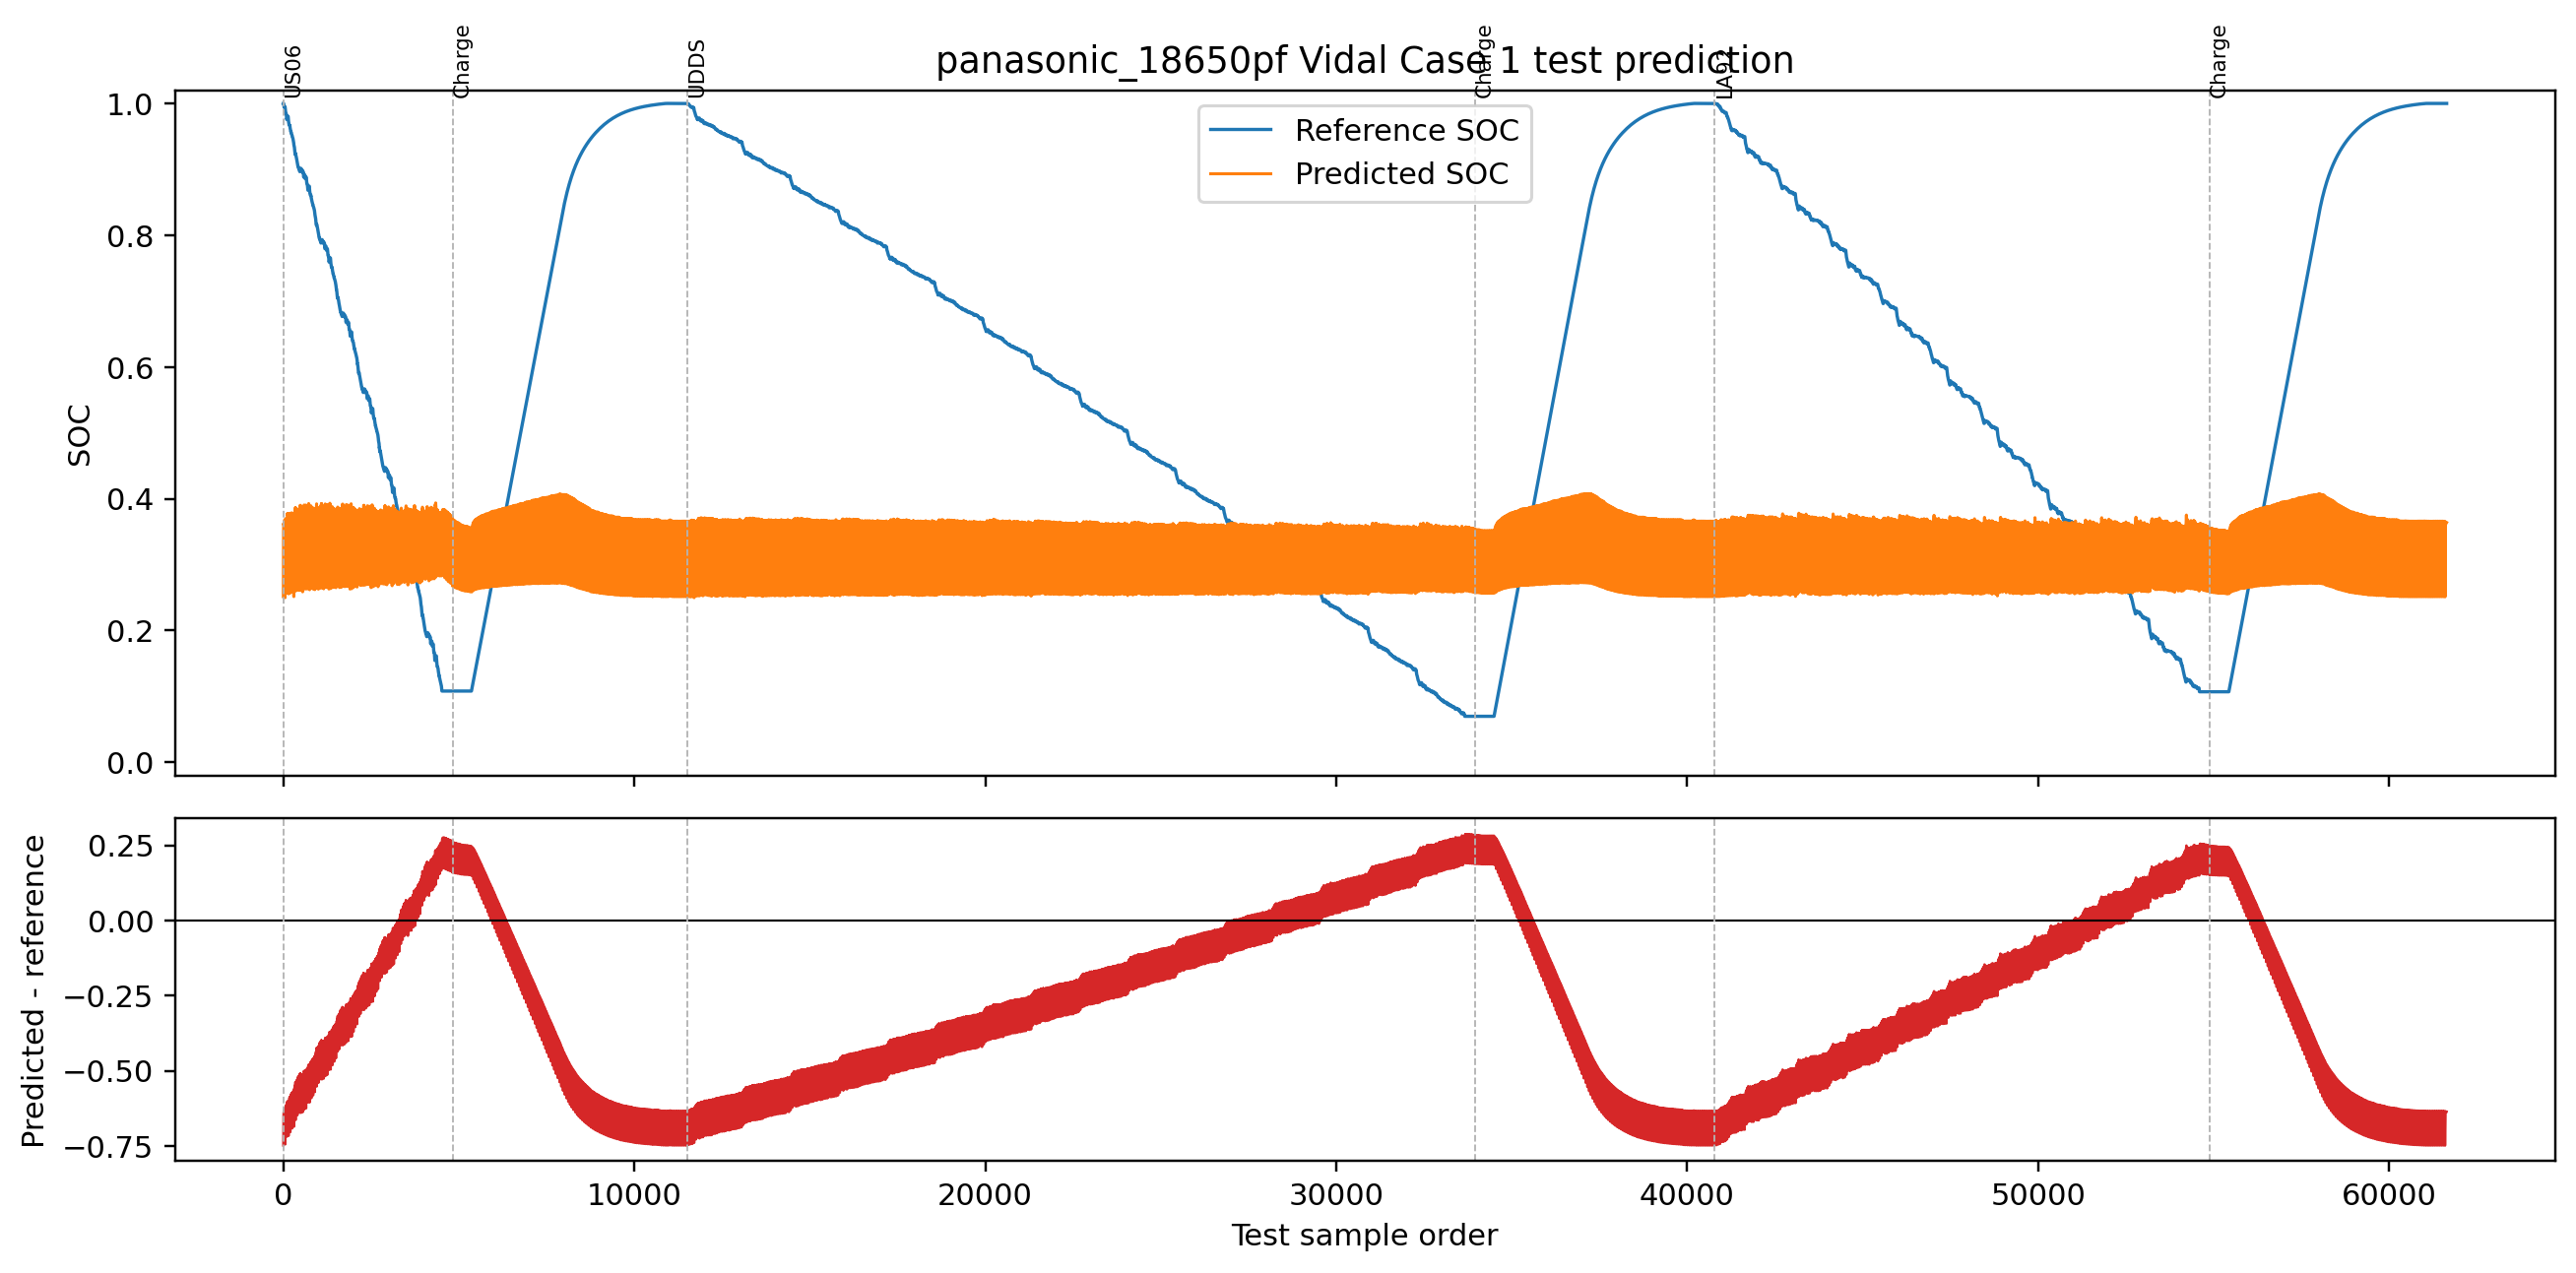

Saved: /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/_smoke/panasonic_18650pf/seed_42/20260716_085748_c4728bba/figures/panasonic_18650pf_case1_training_loss.png


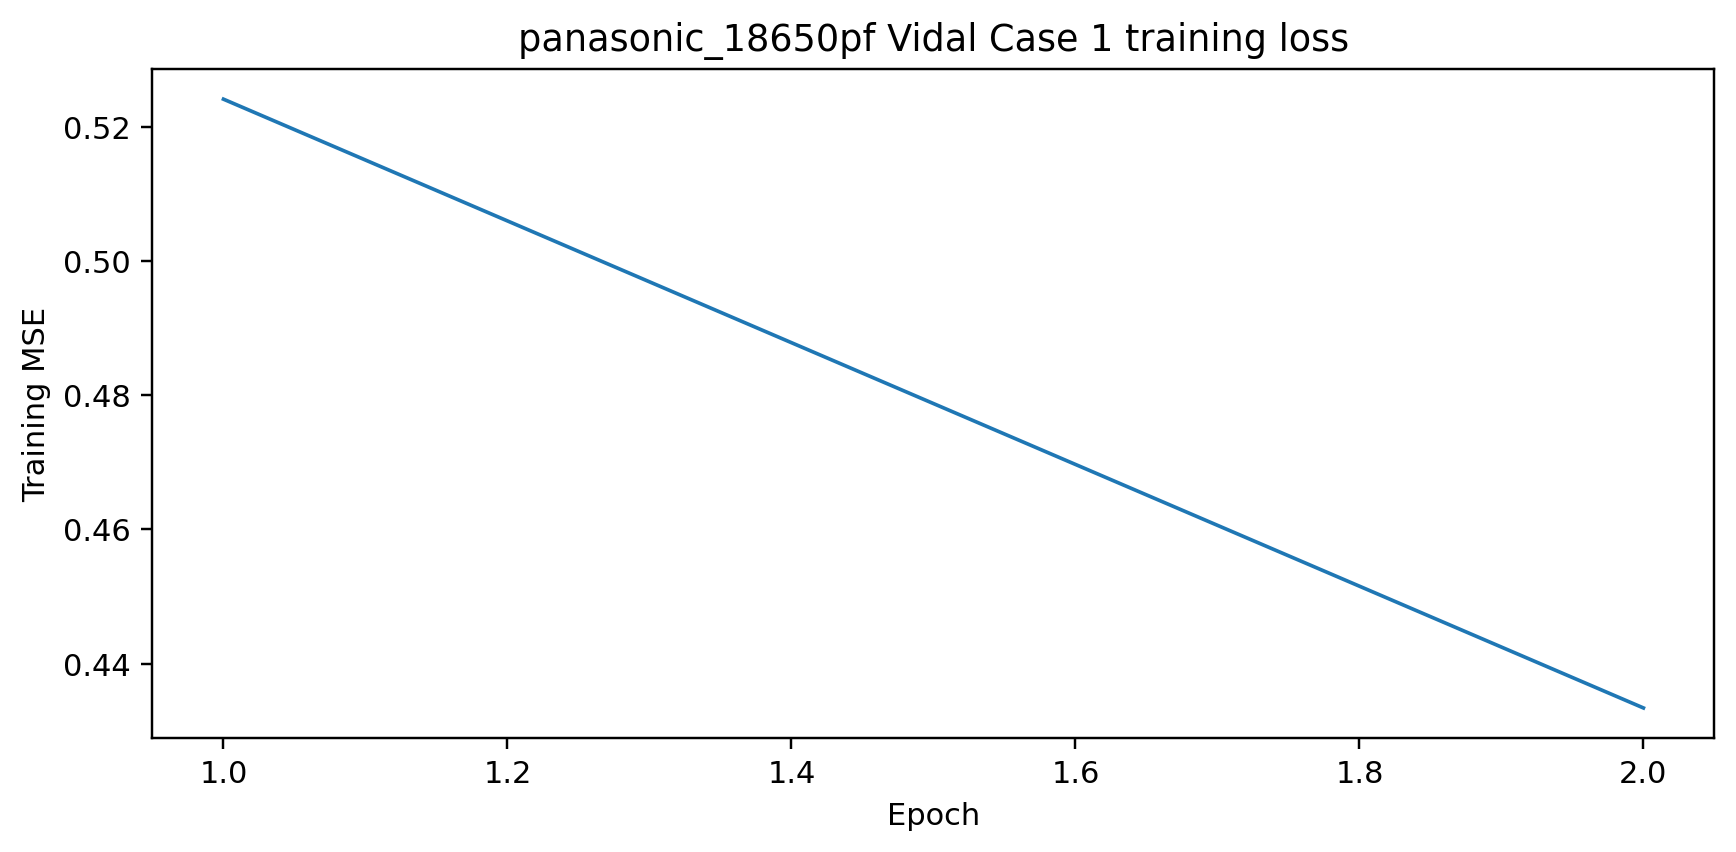

Run: /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/_smoke/samsung_30t/seed_42/20260716_084720_c4728bba
{'mae_fraction': 0.334826927945211, 'mae_percent': 33.4826927945211, 'rmse_fraction': 0.3977449875722714, 'rmse_percent': 39.774498757227136, 'max_error_fraction': 0.7608800679445267, 'max_error_percent': 76.08800679445267, 'bias_fraction': -0.20999811463097717, 'bias_percent': -20.999811463097718, 'r2': -0.3796383874962239}
{'dataset': 'samsung_30t', 'feature_names': ['voltage', 'current', 'temperature'], 'feature_min': [2.4990692138671875, -35.9998893737793, 23.870990753173828], 'feature_max': [4.202008247375488, 11.99921989440918, 33.44041061401367], 'feature_range': [0.0, 1.0], 'fit_split': 'full_train', 'n_fit_samples': 73143, 'git_commit': 'c4728bbaf60430f31640fc0f20958feabefb8c53', 'git_dirty': False, 'timestamp': '2026-07-16T08:47:18.154172+00:00', 'normalization_status': 'reconstruction_assumption', 'sampling_protocol': 'paper_aligned_1hz_reconstructed', 'r

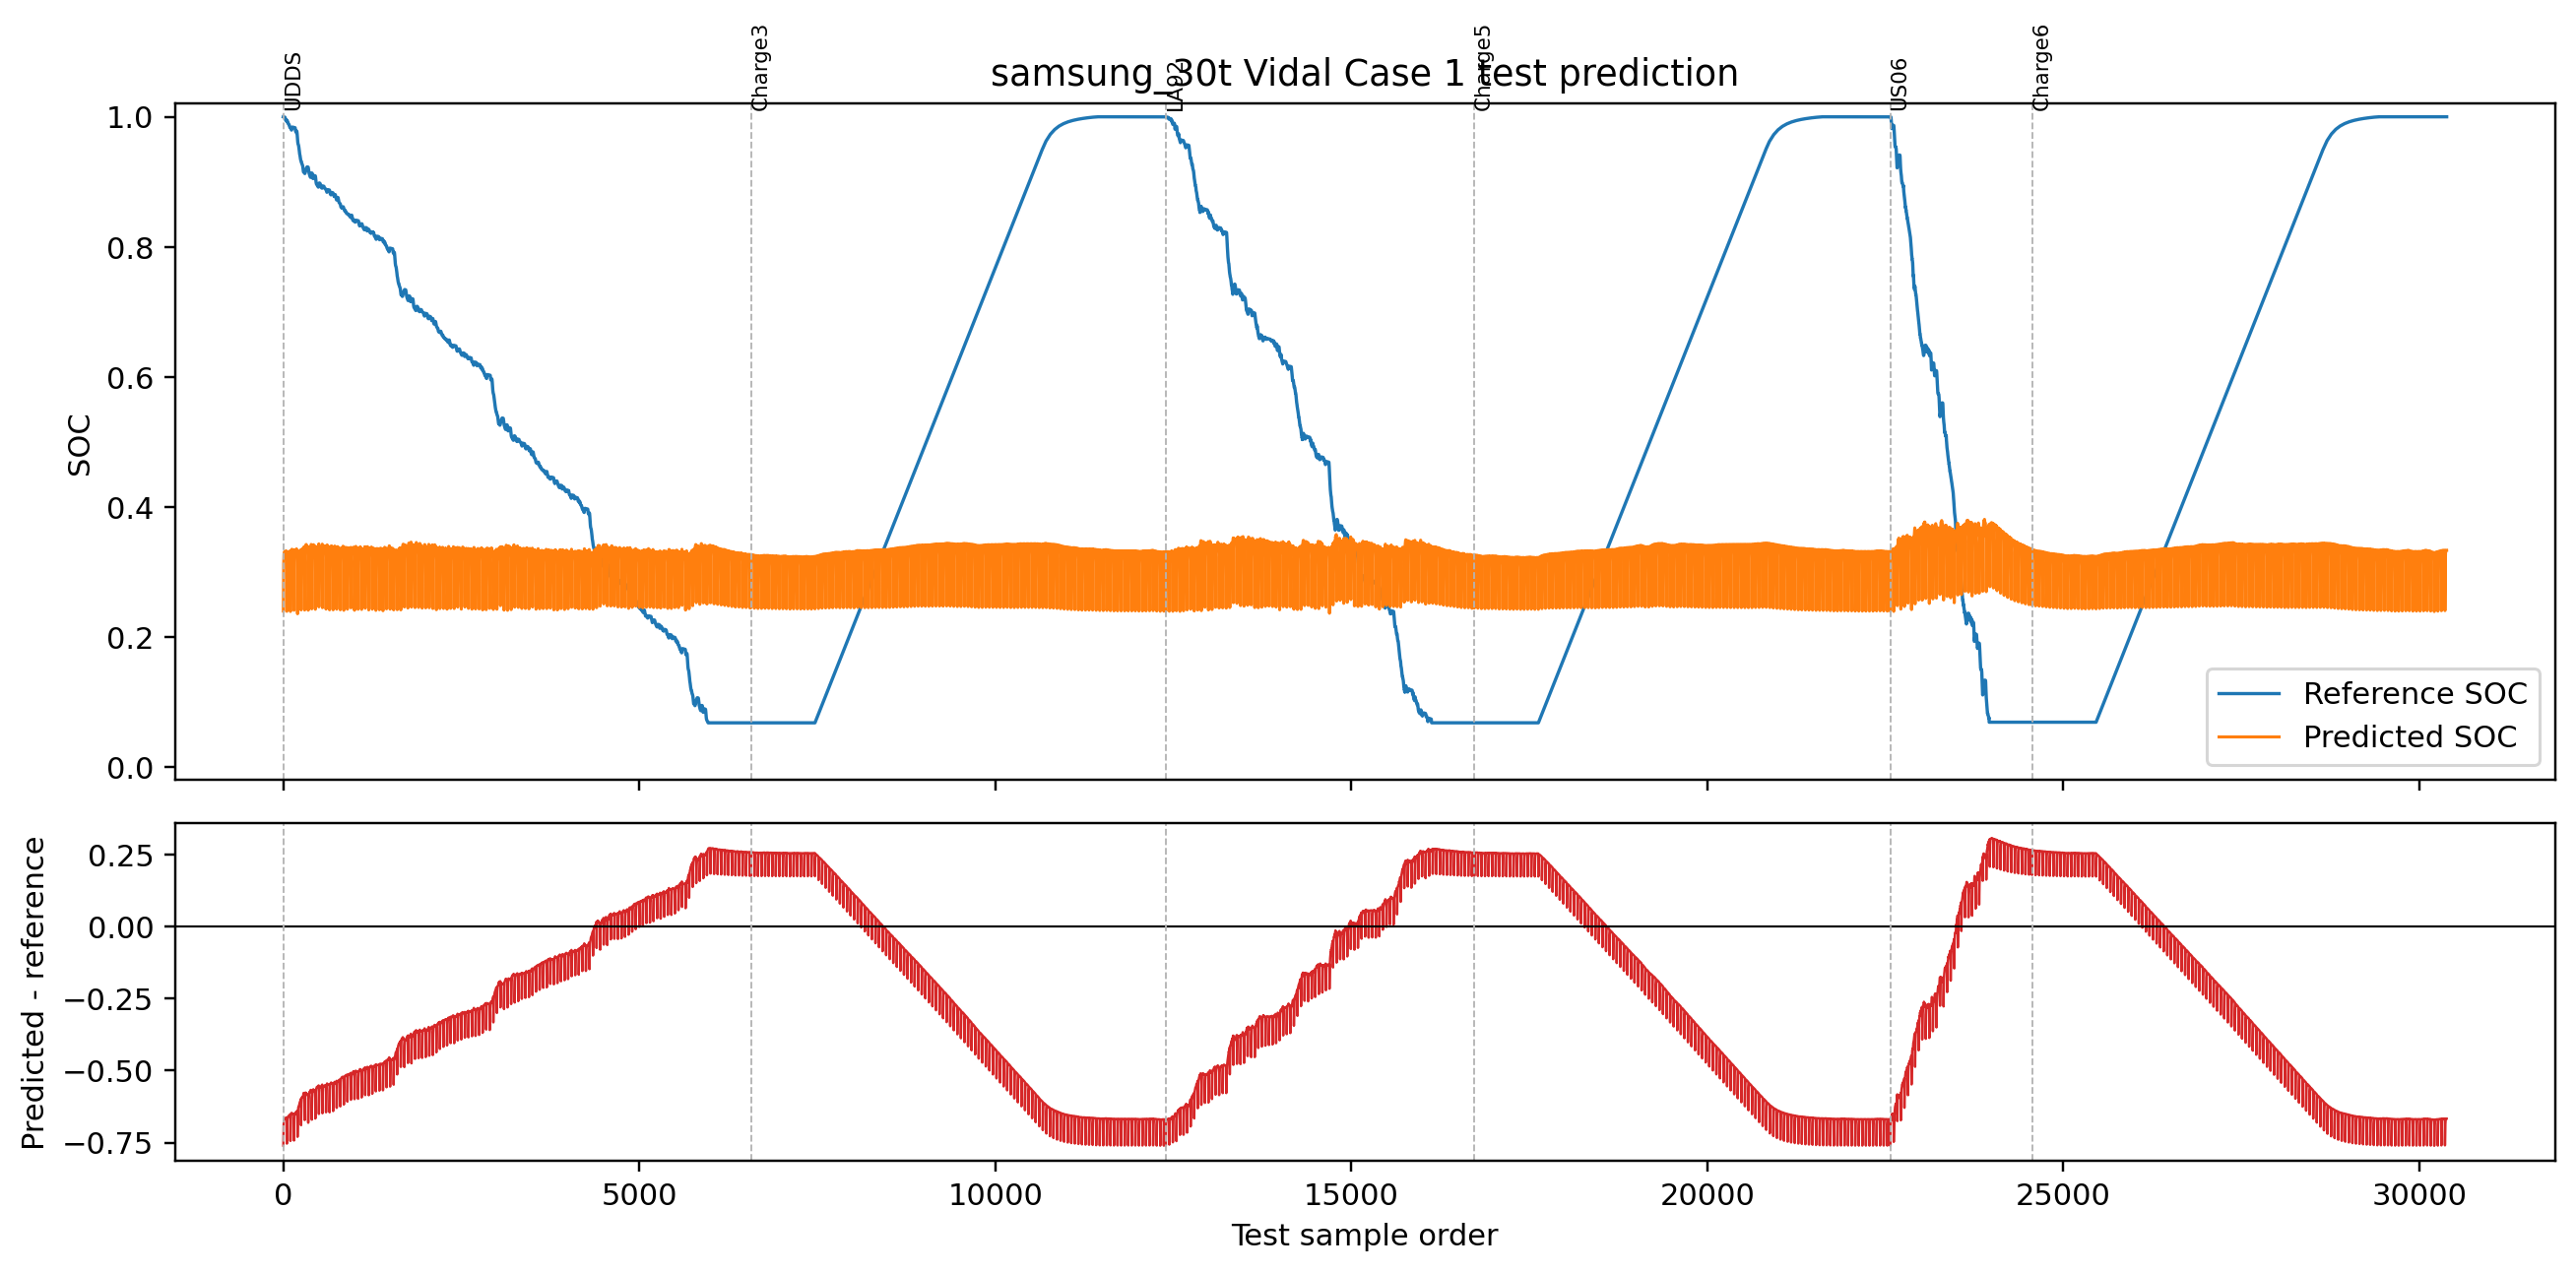

Saved: /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/_smoke/samsung_30t/seed_42/20260716_084720_c4728bba/figures/samsung_30t_case1_training_loss.png


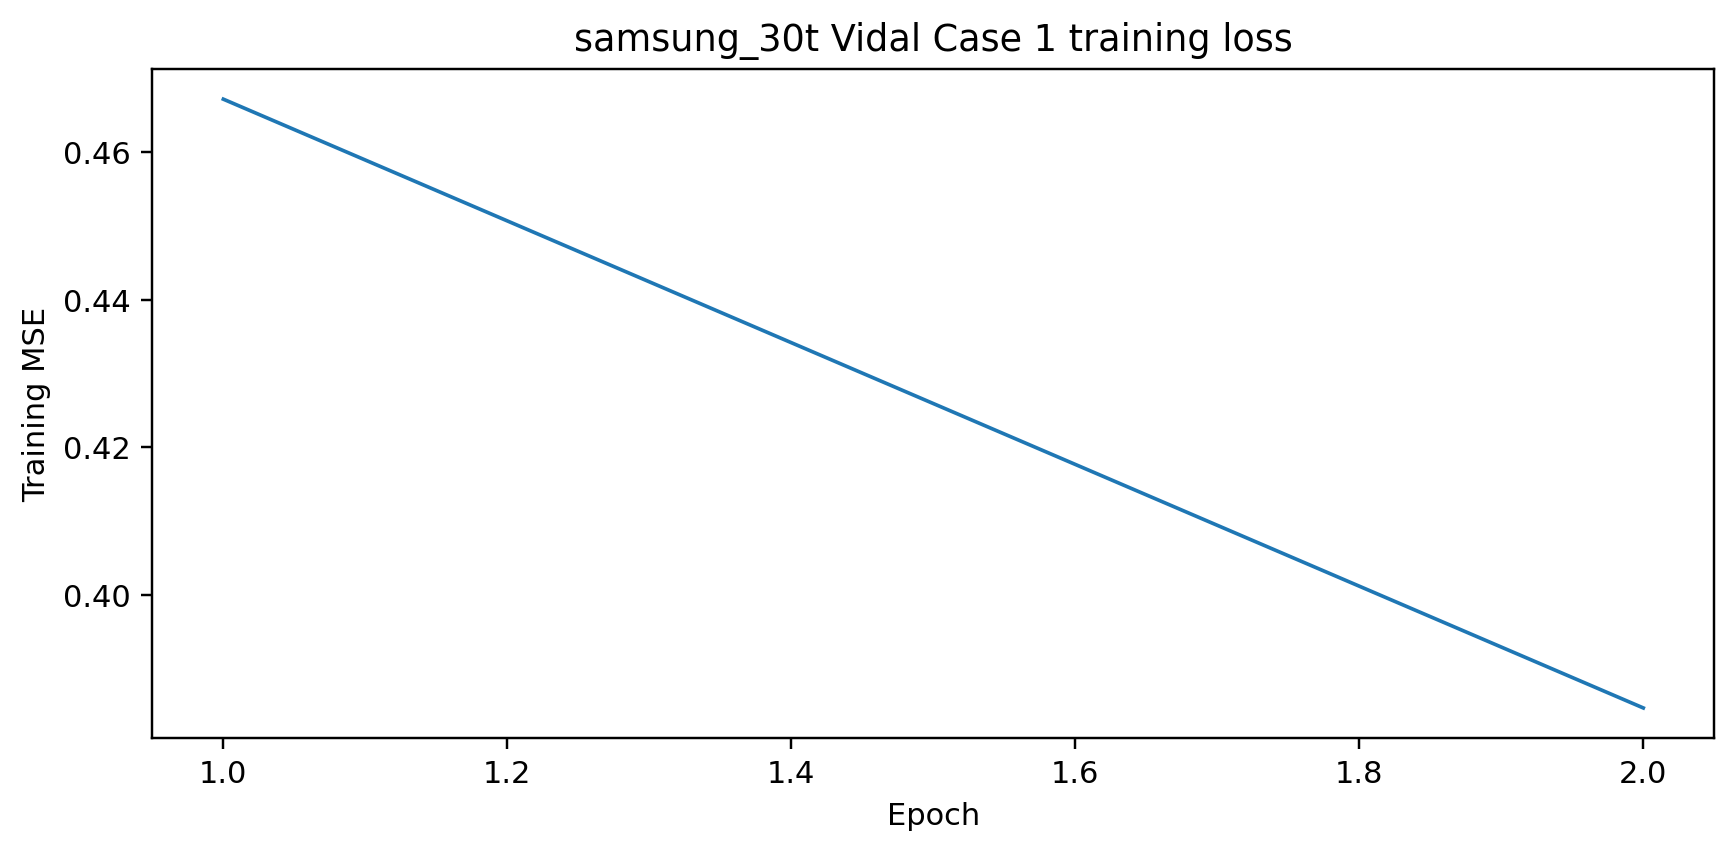

Run: /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/_smoke/samsung_30t/seed_42/20260716_085829_c4728bba
{'mae_fraction': 0.33483480742483307, 'mae_percent': 33.48348074248331, 'rmse_fraction': 0.3977567587167813, 'rmse_percent': 39.77567587167813, 'max_error_fraction': 0.7608856111764908, 'max_error_percent': 76.08856111764908, 'bias_fraction': -0.2100167811271947, 'bias_percent': -21.00167811271947, 'r2': -0.37972004867937326}
{'dataset': 'samsung_30t', 'feature_names': ['voltage', 'current', 'temperature'], 'feature_min': [2.4990692138671875, -35.9998893737793, 23.870990753173828], 'feature_max': [4.202008247375488, 11.99921989440918, 33.44041061401367], 'feature_range': [0.0, 1.0], 'fit_split': 'full_train', 'n_fit_samples': 73143, 'git_commit': 'c4728bbaf60430f31640fc0f20958feabefb8c53', 'git_dirty': False, 'timestamp': '2026-07-16T08:58:28.265355+00:00', 'normalization_status': 'reconstruction_assumption', 'sampling_protocol': 'paper_aligned_1hz_reconstructed', '

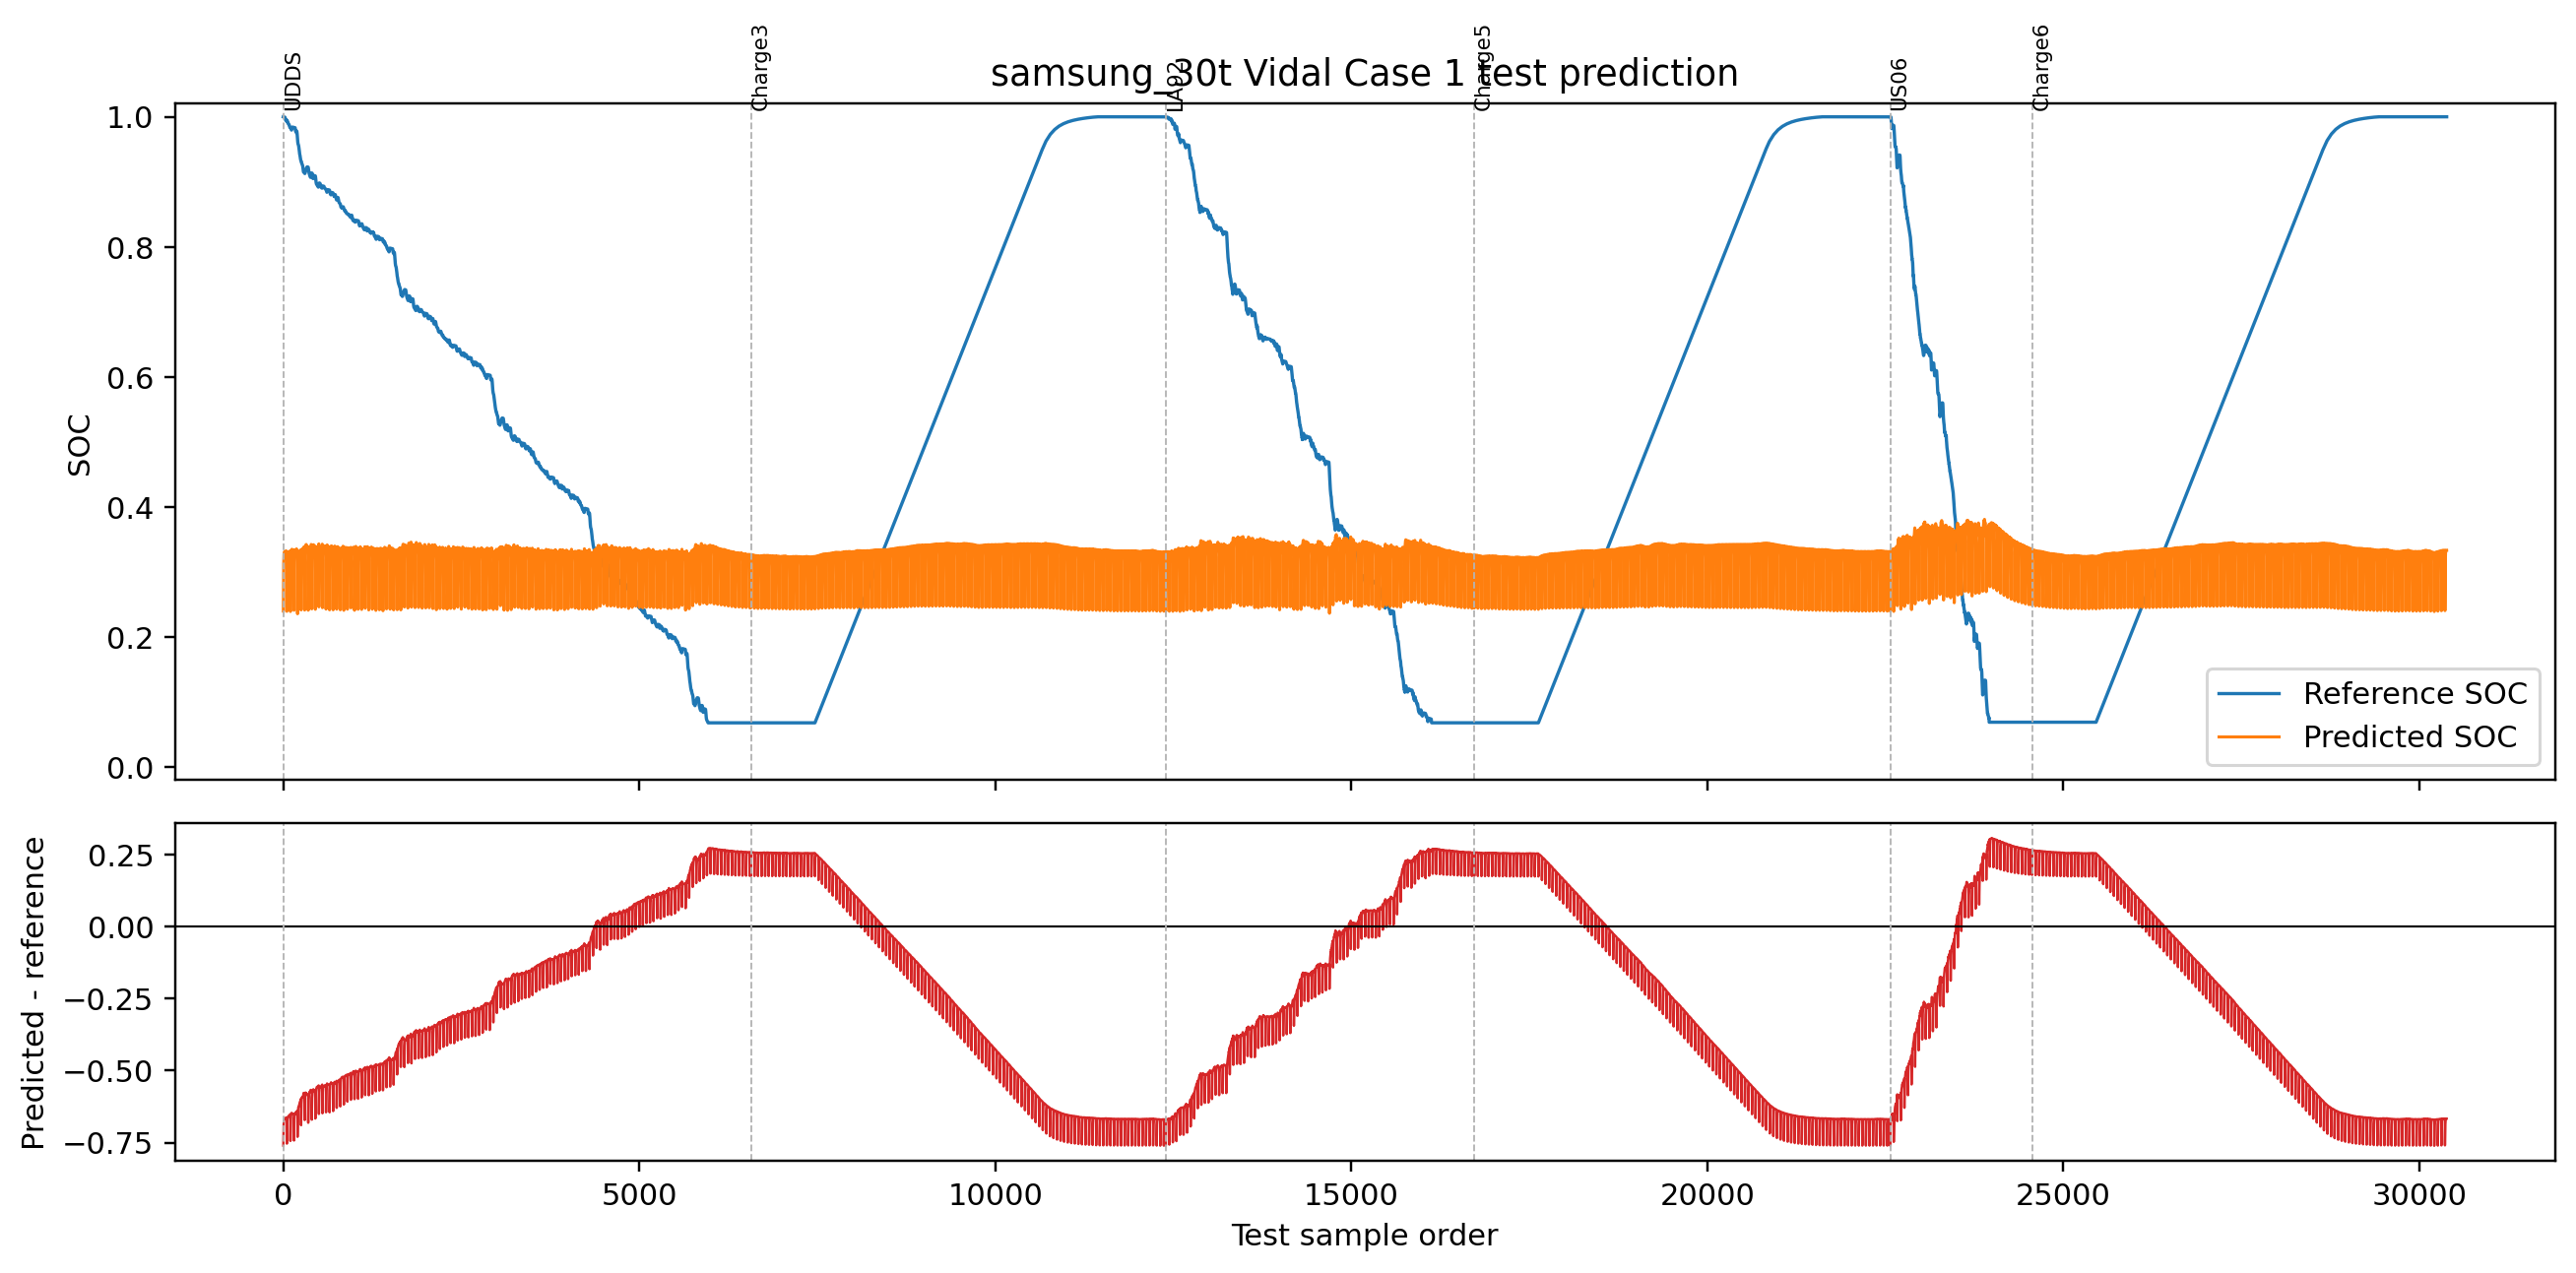

Saved: /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/_smoke/samsung_30t/seed_42/20260716_085829_c4728bba/figures/samsung_30t_case1_training_loss.png


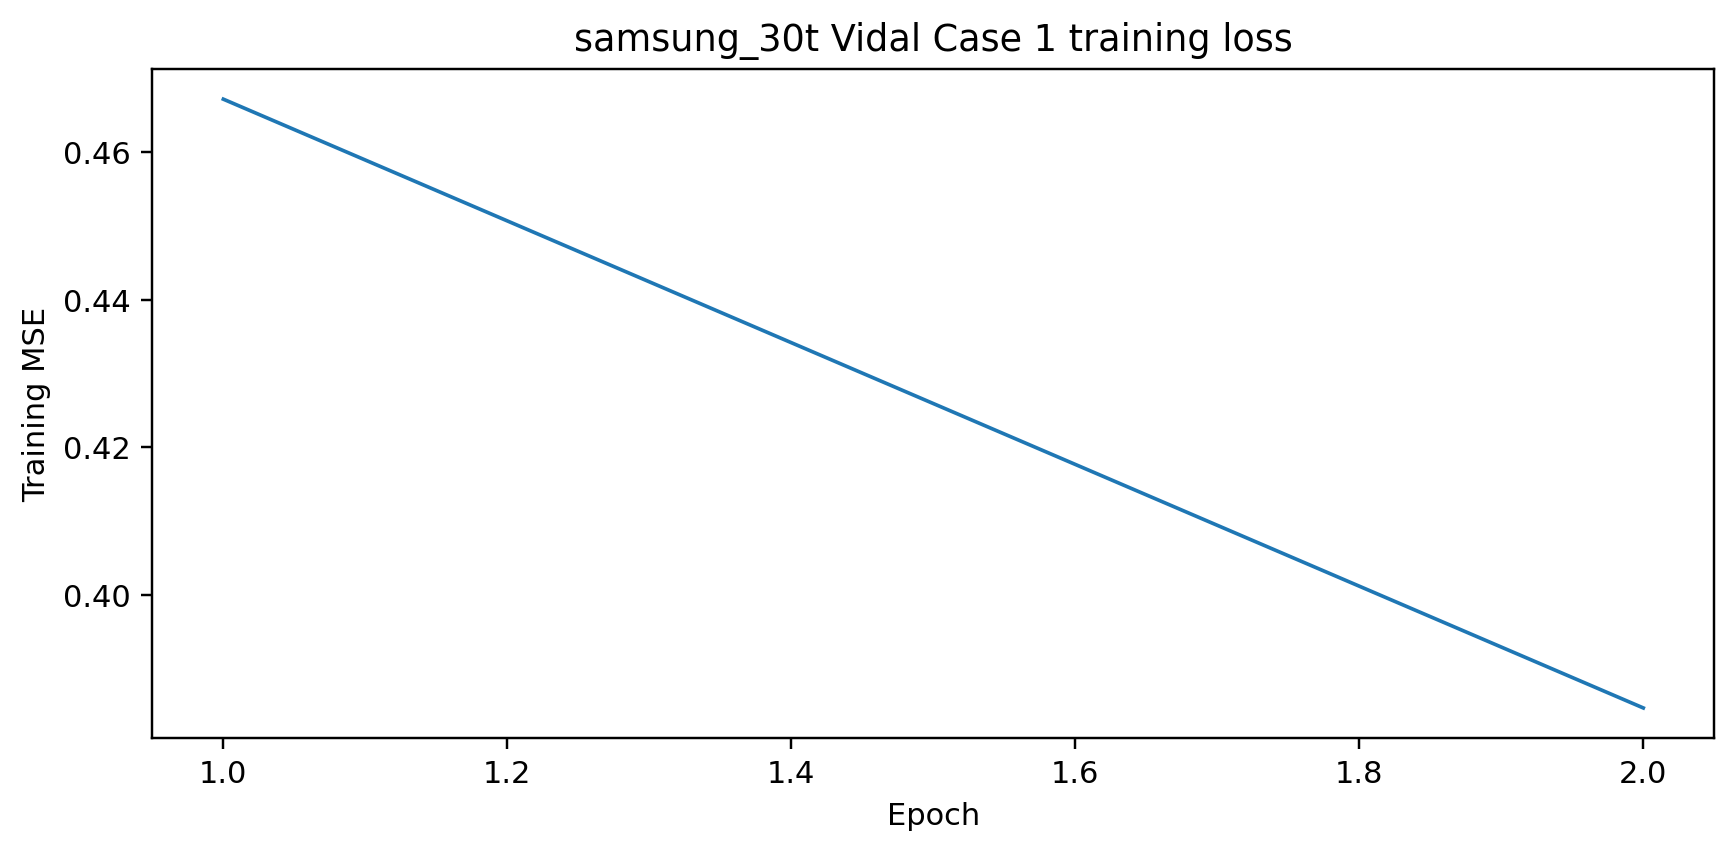

In [9]:
from IPython.display import Image, display
runs = sorted((CASE1_OUTPUT_ROOT / '_smoke').glob('*/*/*'))
for run in runs[-3:]:
    print('Run:', run)
    print(json.loads((run/'metrics.json').read_text()))
    print(json.loads((run/'scaler.json').read_text()))
    for image in sorted((run/'figures').glob('*.png')):
        print('Saved:', image); display(Image(filename=str(image)))

## Formal run reminder
After reviewing the smoke artifacts, commit the code yourself and rerun from a clean checkout with the dataset-specific formal config. Formal mode requires 515 epochs, all training windows, no early stopping, and refuses dirty Git state by default.

Panasonic

In [10]:
!python /content/battery-soc-transfer-benchmark/scripts/run_vidal_case1.py \
  --dataset panasonic_18650pf \
  --config /content/battery-soc-transfer-benchmark/configs/experiments/vidal_case1_panasonic.yaml \
  --input-root /content/drive/MyDrive/battery_soc_benchmark/data/labelled/vidal_sequence_v2 \
  --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1 \
  --cache-root /content/battery_soc_cache/vidal_sequence_v2 \
  --run-mode formal \
  --device auto

[
  {
    "run_dir": "/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba",
    "metrics": {
      "mae_fraction": 0.018969806997124486,
      "mae_percent": 1.8969806997124485,
      "rmse_fraction": 0.03052810844312382,
      "rmse_percent": 3.0528108443123823,
      "max_error_fraction": 0.28443723917007446,
      "max_error_percent": 28.443723917007446,
      "bias_fraction": 4.003034373308498e-05,
      "bias_percent": 0.004003034373308498,
      "r2": 0.9895126910935921
    },
    "metadata": {
      "dataset": "panasonic_18650pf",
      "run_mode": "formal",
      "development_only": false,
      "git_commit": "c4728bbaf60430f31640fc0f20958feabefb8c53",
      "git_dirty": false,
      "device": "cuda",
      "created_at": "2026-07-16T09:05:12.541404+00:00",
      "input_root": "/content/battery_soc_cache/vidal_sequence_v2",
      "inventory_hash": "52698d45dbcdde53df560115d62120e15e986c55302edd888e6b75e87cec1d8d",
 

LG HG2

In [11]:
!python /content/battery-soc-transfer-benchmark/scripts/run_vidal_case1.py \
  --dataset lg_hg2 \
  --config /content/battery-soc-transfer-benchmark/configs/experiments/vidal_case1_lg_hg2.yaml \
  --input-root /content/drive/MyDrive/battery_soc_benchmark/data/labelled/vidal_sequence_v2 \
  --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1 \
  --cache-root /content/battery_soc_cache/vidal_sequence_v2 \
  --run-mode formal \
  --device auto

[
  {
    "run_dir": "/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/lg_hg2/seed_42/20260716_090927_c4728bba",
    "metrics": {
      "mae_fraction": 0.011237088311821977,
      "mae_percent": 1.1237088311821977,
      "rmse_fraction": 0.01845178445803164,
      "rmse_percent": 1.845178445803164,
      "max_error_fraction": 0.19224277138710022,
      "max_error_percent": 19.224277138710022,
      "bias_fraction": 0.004065026844760076,
      "bias_percent": 0.4065026844760076,
      "r2": 0.9969790443845763
    },
    "metadata": {
      "dataset": "lg_hg2",
      "run_mode": "formal",
      "development_only": false,
      "git_commit": "c4728bbaf60430f31640fc0f20958feabefb8c53",
      "git_dirty": false,
      "device": "cuda",
      "created_at": "2026-07-16T09:10:07.318935+00:00",
      "input_root": "/content/battery_soc_cache/vidal_sequence_v2",
      "inventory_hash": "3697fe8823f43b95768c20413b10f39836a3631b5f755ac06d0dc1dc5c20c56e",
      "train_records": 16,


Samsung 30T

In [12]:
!python /content/battery-soc-transfer-benchmark/scripts/run_vidal_case1.py \
  --dataset samsung_30t \
  --config /content/battery-soc-transfer-benchmark/configs/experiments/vidal_case1_samsung_30t.yaml \
  --input-root /content/drive/MyDrive/battery_soc_benchmark/data/labelled/vidal_sequence_v2 \
  --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1 \
  --cache-root /content/battery_soc_cache/vidal_sequence_v2 \
  --run-mode formal \
  --device auto

[
  {
    "run_dir": "/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/samsung_30t/seed_42/20260716_091258_c4728bba",
    "metrics": {
      "mae_fraction": 0.017129236901774664,
      "mae_percent": 1.7129236901774665,
      "rmse_fraction": 0.028078941683251413,
      "rmse_percent": 2.8078941683251415,
      "max_error_fraction": 0.2322068214416504,
      "max_error_percent": 23.22068214416504,
      "bias_fraction": 0.0014827043374178086,
      "bias_percent": 0.14827043374178087,
      "r2": 0.9931242938320936
    },
    "metadata": {
      "dataset": "samsung_30t",
      "run_mode": "formal",
      "development_only": false,
      "git_commit": "c4728bbaf60430f31640fc0f20958feabefb8c53",
      "git_dirty": false,
      "device": "cuda",
      "created_at": "2026-07-16T09:13:19.959770+00:00",
      "input_root": "/content/battery_soc_cache/vidal_sequence_v2",
      "inventory_hash": "0068a194d24718ee9a3c3e0e0ed7ad1b9f10c9109ee039e2c1289fd514eed3aa",
      "train_re

| Battery     | Paper RMSE | Ours RMSE | Paper MAE | Ours MAE | Paper MAX | Ours MAX |
| ----------- | ---------: | --------: | --------: | -------: | --------: | -------: |
| Panasonic   |        2.6 |      3.05 |       2.2 |     1.90 |      10.1 |    28.44 |
| LG HG2      |        1.9 |      1.85 |       1.3 |     1.12 |      13.1 |    19.22 |
| Samsung 30T |        2.3 |      2.81 |       1.6 |     1.71 |      14.3 |    23.22 |
